# Notebook 01 — Data Loading & Exploratory Data Analysis (EDA)

**Project:** Student Wellbeing & Mental Health Risk — Educational Classification Prototype  
**Notebook goal:** Understand what is in the student dataset, check data quality, and describe patterns without making clinical claims.

> **Important:** This is a learning project, **not** a diagnosis, clinical screening tool, disciplinary system, or student-selection tool. Predictions are statistical estimates from a dataset, not judgments about real students.

## How to use this notebook

1. Read the **What to do** and **Why it matters** sections.
2. Write **your own Python code** in each blank code cell directly below the instructions.
3. Check the **Example of expected output** (illustrative only; your values will differ).
4. Write your findings in the **Your interpretation** prompts before moving on.

**You will learn to:**
- Load and inspect a dataset confidently.
- Recognize missing values, duplicates, inconsistent data, and unusual values.
- Explore numerical/categorical variables and target balance.
- Explain charts and correlations carefully, without claiming causation.


---

## 1. Set up the notebook and locate the dataset

### What to do
- Import the libraries you will need for reading tables, numerical operations, and charts.
- Choose the **real path** to your CSV dataset in `data/raw/`.
- Check that the file exists before proceeding.

### Why it matters
A reproducible project begins with a clear data source and organized imports.

### Example of expected output

**Illustrative:** `Dataset found: data/raw/students.csv`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Imports run without errors.
- [ ] Dataset path is correct.

### Watch out
No dataset was provided with these notebooks. Use your own CSV, and do not assume a specific file name.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

FILE_PATH = "/home/mestry/Documents/youcode/Pr-diction-du-risque-de-sant-mentale-chez-les-tudiants/student-mental-health/data/raw/student_mental_health.csv"

try:
    data = pd.read_csv(FILE_PATH)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file at {FILE_PATH} was not found.")

Dataset loaded successfully.


---

## 2. Load the data and inspect its shape

### What to do
- Load the CSV into a DataFrame.
- Show the first and last few rows.
- Display total number of rows and columns; list all column names.

### Why it matters
Before cleaning or modeling, you must know the structure of your data.

### Example of expected output

**Illustrative:** `Rows: 2,000 | Columns: 12`

| age | study_hours | sleep_hours | target |
|---:|---:|---:|---|
| 21 | 5 | 7 | low |
| 23 | 8 | 5 | high |

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] DataFrame loads successfully.
- [ ] Row and column counts are clear.
- [ ] You understand what one row represents.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [108]:
dataSet = pd.read_csv(FILE_PATH)

display(dataSet.head())
display(dataSet.tail())

dataSet.info()

display(dataSet.describe().T)

range_checks = {
    "Age": (dataSet["Age"].between(17, 100) | dataSet["Age"].isna()).all(),
    "Year_of_Study": (dataSet["Year_of_Study"].between(1, 5) | dataSet["Year_of_Study"].isna()).all(),
    "GPA": (dataSet["GPA"].between(0, 4) | dataSet["GPA"].isna()).all(),
    "Sleep_Hours": (dataSet["Sleep_Hours"].between(0, 24) | dataSet["Sleep_Hours"].isna()).all(),
    "Attendance_Rate": (dataSet["Attendance_Rate"].between(0, 100) | dataSet["Attendance_Rate"].isna()).all(),
    "Financial_Stress": (dataSet["Financial_Stress"].between(1, 10) | dataSet["Financial_Stress"].isna()).all(),
    "Family_Support": (dataSet["Family_Support"].between(1, 10) | dataSet["Family_Support"].isna()).all(),
}
display(pd.Series(range_checks))

expected_categories = {
    "Gender": {"Male", "Female", "Other", "Non-binary"},
    "Physical_Activity": {"Low", "Moderate", "High"},
    "Part_Time_Job": {"Yes", "No"},
    "Diet_Quality": {"Poor", "Average", "Good"},
    "Previous_Mental_Health_History": {"Yes", "No"},
    "Mental_Health_Risk": {"Low", "Medium", "High"},
}
for column, allowed in expected_categories.items():
    unexpected = sorted(set(dataSet[column].dropna().unique()) - allowed)
    print(f"{column}: unexpected values = {unexpected}")


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


Age                 True
Year_of_Study       True
GPA                 True
Sleep_Hours         True
Attendance_Rate     True
Financial_Stress    True
Family_Support      True
dtype: bool

Gender: unexpected values = []
Physical_Activity: unexpected values = []
Part_Time_Job: unexpected values = []
Diet_Quality: unexpected values = []
Previous_Mental_Health_History: unexpected values = []
Mental_Health_Risk: unexpected values = []


### Your interpretation (write in your own words)
Which columns look like input features? Which column might be the target?

**My notes:**  Mental_health_risk


---

## 3. Identify data types and meanings

### What to do
- Inspect each column’s data type.
- Classify columns as **numerical**, **categorical**, **identifier**, or **target**.
- Check whether numerical-looking columns are stored as text.

### Why it matters
Different variable types need different charts, missing-value treatments, and encodings.

### Example of expected output

**Illustrative:** `age → integer; gender → category/text; sleep_hours → float; risk_level → target`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Each variable has a documented meaning.
- [ ] Potential identifier columns are listed.
- [ ] Suspicious data types are noted.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [109]:
data.dtypes


Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

### Your interpretation (write in your own words)
Which columns should not be used as predictors (for example student ID)?

**My notes:**  student ID

---

## 4. Audit missing values, duplicates, and invalid entries

### What to do
- Count missing entries per column, with percentages.
- Count exact duplicate rows.
- Look for inconsistent labels, impossible values, blank strings, and surprising category spelling.
- **Only report problems here;** decide the cleaning rules in Notebook 02.

### Why it matters
Data quality problems can distort findings and reduce model reliability.

### Example of expected output

**Illustrative:**

| Column | Missing | Missing % |
|---|---:|---:|
| sleep_hours | 42 | 2.1% |
| study_hours | 0 | 0% |

`Duplicate rows: 6`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Missingness and duplicate counts are visible.
- [ ] Possible invalid entries have been identified.
- [ ] Raw data remains unchanged.

### Watch out
Do not silently delete rows with missing values or outliers. Avoid treating a rare but valid student response as an error.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [110]:
missing_values = dataSet.isnull().sum()
duplicated_rows = dataSet.duplicated().sum()

print(f"duplicated rows: {duplicated_rows} \n")

missing_values_percentage = (missing_values / len(dataSet)) * 100

display(missing_values, missing_values_percentage)

duplicated rows: 0 



Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

Student_ID                        0.00
Age                               0.00
Gender                            0.00
Year_of_Study                     0.00
Sleep_Hours                       3.10
Study_Hours_Per_Week              0.00
GPA                               1.90
Social_Media_Hours                2.90
Screen_Time_Hours                 0.00
Physical_Activity                 0.00
Financial_Stress                  4.55
Family_Support                    2.70
Attendance_Rate                   2.35
Part_Time_Job                     0.00
Diet_Quality                      3.45
Previous_Mental_Health_History    0.00
Mental_Health_Risk                0.00
dtype: float64

### Your interpretation (write in your own words)
Which issues appear most important, and how could they affect interpretation?

**My notes:**  \n_Replace this with your explanation._

---

## 5. Produce descriptive statistics

### What to do
- Calculate mean, median, standard deviation, minimum, maximum, and quartiles for numerical columns.
- Calculate counts and proportions for categories.
- Identify suspicious ranges.

### Why it matters
These summaries describe the dataset before you create charts or models.

### Example of expected output

**Illustrative:** `sleep_hours: mean=6.7, median=7, min=1, max=13`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Numerical statistics are displayed.
- [ ] Category counts are displayed.
- [ ] Strange values are documented.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [111]:
display(dataSet.describe().T)

numeric_columns = dataSet.select_dtypes(include="number").columns
outlier_counts = {}
for column in numeric_columns:
    values = dataSet[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_counts[column] = int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())
display(pd.Series(outlier_counts, name="IQR_outlier_count").sort_values(ascending=False))


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


Social_Media_Hours      20
Attendance_Rate         12
GPA                      9
Study_Hours_Per_Week     7
Screen_Time_Hours        7
Age                      4
Sleep_Hours              2
Year_of_Study            0
Financial_Stress         0
Family_Support           0
Name: IQR_outlier_count, dtype: int64

### Your interpretation (write in your own words)
What does the difference between mean and median suggest?

**My notes:**  \n_Replace this with your explanation._

---

## 6. Explore distributions and unusual values

### What to do
- Create histograms for numerical features and bar plots for categorical features.
- Use boxplots to spot potential outliers.
- Compare shapes, skewness, spread, and unusual peaks.

### Why it matters
Visualization helps you see patterns that tables may hide.

### Example of expected output

**Illustrative observation:** “Most reported sleep durations are between 6 and 8 hours, while a few responses are unusually low.”

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] At least two numerical distributions are charted.
- [ ] At least one categorical variable is charted.
- [ ] Potential outliers are described, not automatically removed.

### Watch out
Outliers can be genuine responses. Investigate before choosing whether to cap or remove them.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

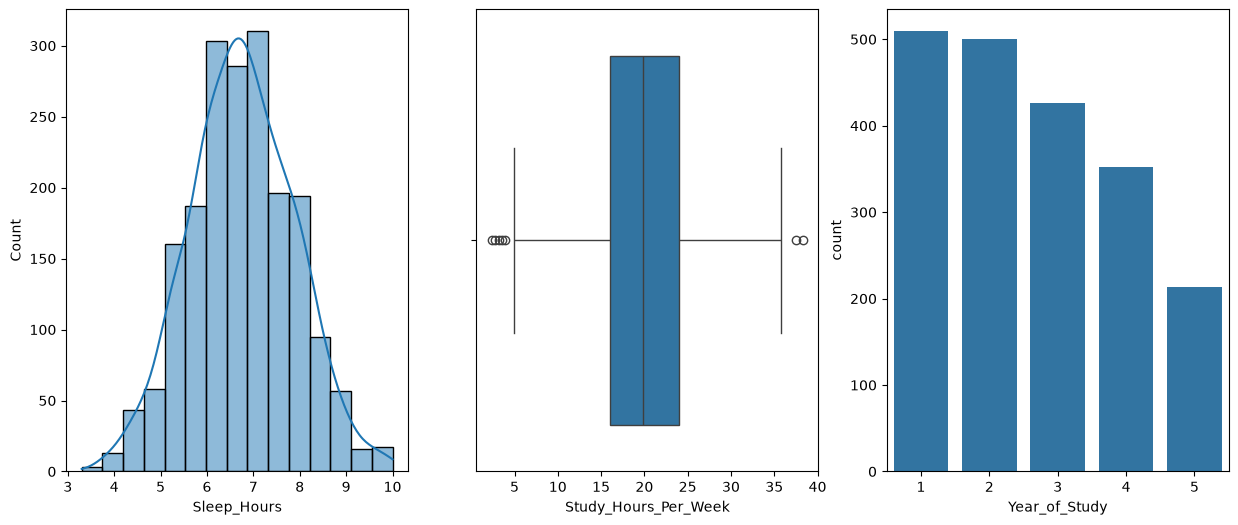

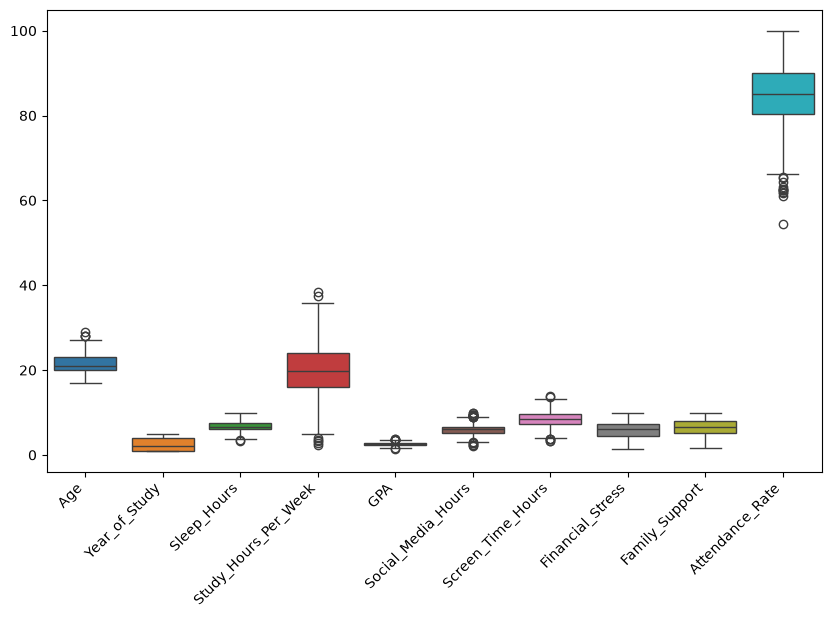

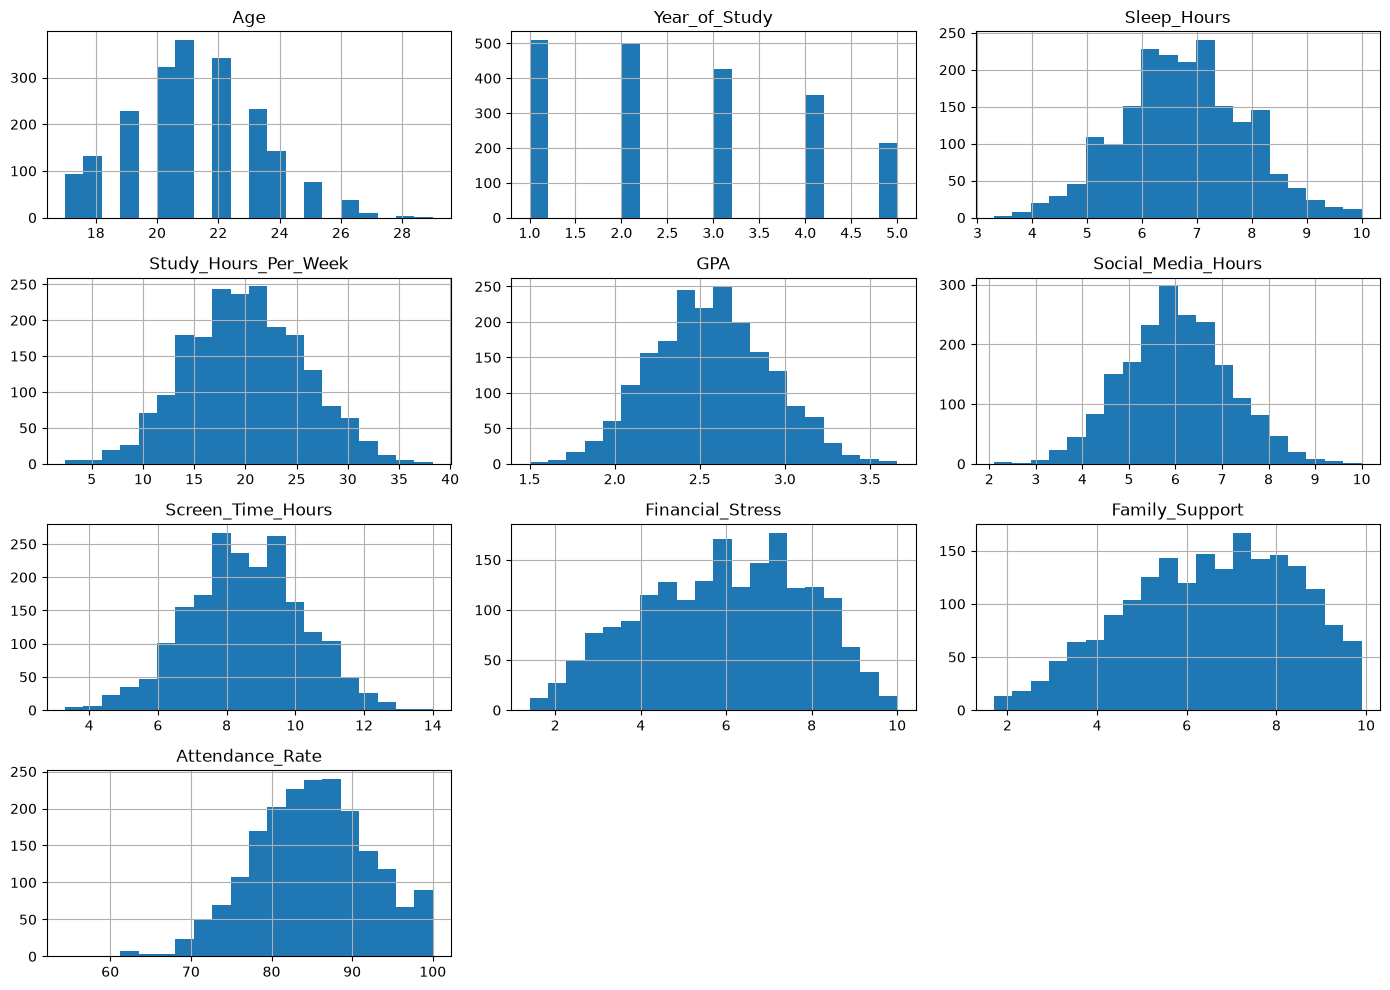

In [112]:
fig, ax = plt.subplots(1, 3, figsize=(15, 6))

sns.histplot(data=dataSet, x='Sleep_Hours', bins=15, kde=True, ax=ax[0])
sns.boxplot(data=dataSet, x='Study_Hours_Per_Week', ax=ax[1])
sns.countplot(data=dataSet, x='Year_of_Study', ax=ax[2])
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=dataSet.select_dtypes(include="number"))
plt.xticks(rotation=45, ha="right")
plt.show()


dataSet.select_dtypes(include="number").hist(figsize=(14, 10), bins=20)
plt.tight_layout()




### Your interpretation (write in your own words)
What story does each chart tell?

**My notes:**  \n_Replace this with your explanation._

---

## 7. Identify and study the target variable

### What to do
- Choose the **actual** target column from your dataset and explain how it is defined.
- Show category counts and class percentages.
- Plot class distribution.
- Flag strong class imbalance.

### Why it matters
You cannot train a meaningful classifier without a clearly defined label. Class balance affects evaluation and training.

### Example of expected output

**Illustrative:** `low: 1,400 (70%); high: 600 (30%)`

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Target column is explicitly identified.
- [ ] Label meaning and origin are documented.
- [ ] Class distribution is displayed.

### Watch out
Do not call a survey label a diagnosis. If the target itself is unclear, document the limitation before training.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

In [113]:

target_column = 'Mental_Health_Risk' #mental health risk is the target variable we want to predict because it indicates the level of mental health risk for students, which is the main focus of our analysis and prediction model.

class_distribution = pd.DataFrame({
    "Count": dataSet[target_column].value_counts(),
    "Percentage": (dataSet[target_column].value_counts(normalize=True) * 100).round(2)
})

display(class_distribution)




,Count,Percentage
Mental_Health_Risk,,
High,680,34.0
Medium,660,33.0
Low,660,33.0


### Your interpretation (write in your own words)
Does the target represent a self-reported label, a survey category, or something else? What does it **not** prove?

**My notes:**  \n_Replace this with your explanation._

---

## 8. Study feature–target relationships

### What to do
- Compare numerical feature distributions across target classes.
- Compare categorical feature proportions across target classes.
- Describe differences without asserting causes.

### Why it matters
This helps identify potentially informative features and exposes data collection issues.

### Example of expected output

**Illustrative observation:** “In this sample, the high-risk-labeled group reports fewer sleep hours on average; this does not show that lack of sleep caused the label.”

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Two numerical features are compared with the target.
- [ ] At least one categorical comparison is shown.
- [ ] Interpretation avoids causal claims.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

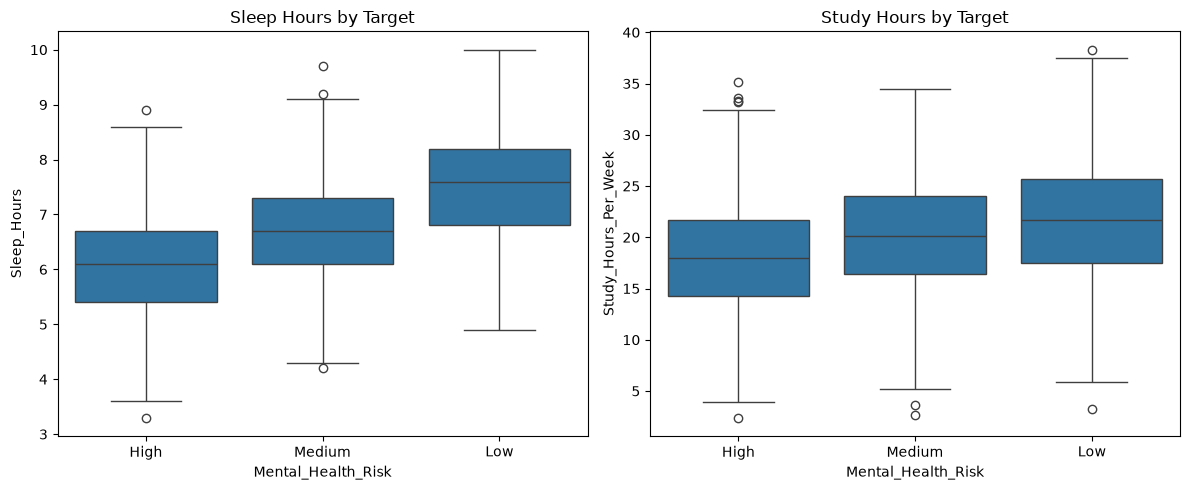

In [114]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=dataSet,
    x= target_column,
    y="Sleep_Hours",
    ax=ax[0]
)
ax[0].set_title("Sleep Hours by Target")

sns.boxplot(
    data=dataSet,
    x=target_column,
    y="Study_Hours_Per_Week",
    ax=ax[1]
)
ax[1].set_title("Study Hours by Target")

plt.tight_layout()
plt.show()


### Your interpretation (write in your own words)
Which features appear associated with the target? Could confounding variables explain them?

**My notes:**  \n_Replace this with your explanation._

---

## 9. Examine correlations and leakage candidates

### What to do
- Build a correlation matrix for applicable numerical fields.
- Visualize it as a heatmap.
- Check highly redundant features.
- Identify variables that may reveal the target directly or were collected after the label was assigned.

### Why it matters
Strong correlations can show redundancy or suspicious target leakage; they do not measure causation.

### Example of expected output

**Illustrative:** `corr(study_hours, stress_score)=0.48` (example only)

*The sample above is illustrative, not a result from your dataset.*

### Success checklist
- [ ] Correlation heatmap exists.
- [ ] At least two correlations are interpreted.
- [ ] Potential leakage features are noted.

### Watch out
Do not use the test set to make model-selection or feature-selection decisions. Exploratory findings can guide hypotheses, but confirm them using training-only validation.


### Your code
Write your Python code in the empty cell below. No solution is supplied.

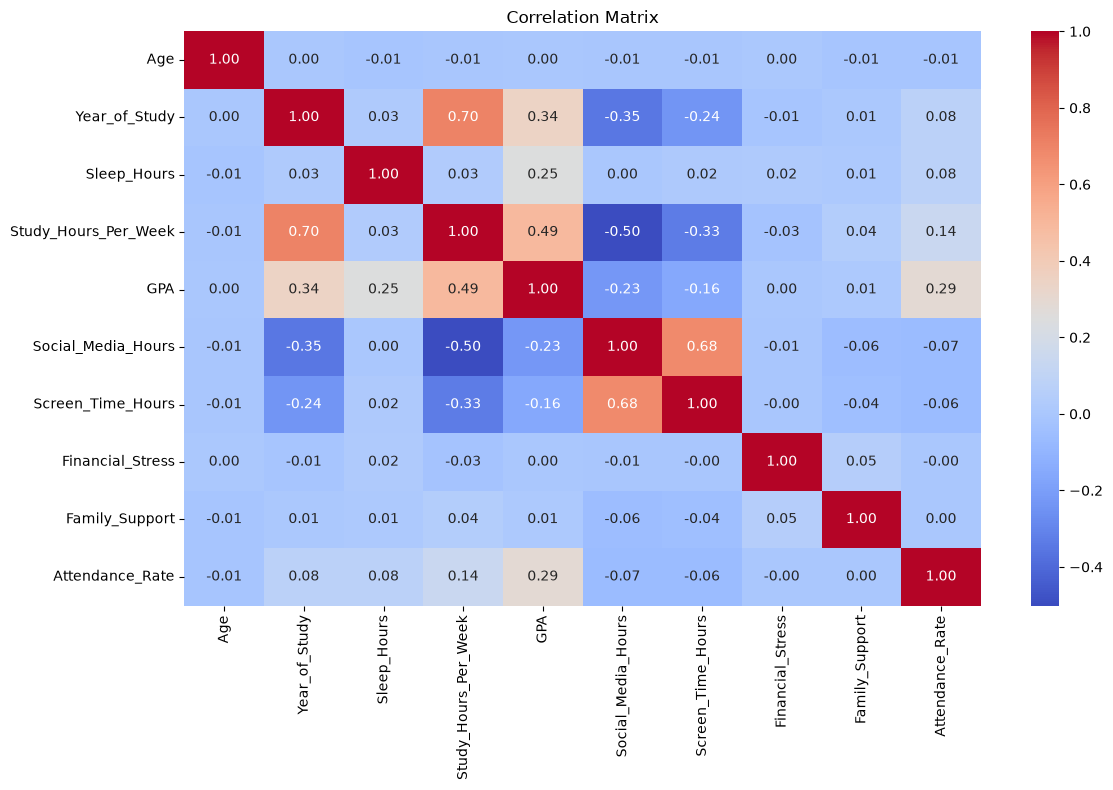

In [115]:
numeric_data = dataSet.select_dtypes(include="number")

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()



### Your interpretation (write in your own words)
Can you explain why correlation does not prove causation?

**My notes:**  \n_Replace this with your explanation._

---

## Final EDA deliverables

- [ ] Data dictionary (feature names, meaning, types, and target definition)
- [ ] Data quality summary
- [ ] Descriptive statistics and readable charts
- [ ] Target class distribution
- [ ] Main associations, possible leakage, and limitations
- [ ] Short written EDA conclusion

**Next notebook:** `02_preprocessing.ipynb` — split the dataset, fit cleaning/preprocessing **only on training data**, and prevent leakage.
